In [1]:
import os
# https://stackoverflow.com/questions/20554074/sklearn-omp-error-15-initializing-libiomp5md-dll-but-found-mk2iomp5md-dll-a
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"


from scipy import stats
import numpy as np
from scipy.optimize import minimize, LinearConstraint
import matplotlib.pyplot as plt
from dataclasses import dataclass

import cv2

In [2]:
import importlib
import sys
from pathlib import Path
if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")
print(sys.path)

['p:\\Programs\\miniconda3\\envs\\master-pytorch\\python313.zip', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\DLLs', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch', '', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32\\lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\Pythonwin', 'd:\\Studium\\Masters\\dev\\scripts\\..\\src']


In [3]:
import model
import distribution
import utils
import model_utils
import train_utils
import domain
import parameter_model

importlib.reload(model)
importlib.reload(distribution)
importlib.reload(utils)
importlib.reload(model_utils)
importlib.reload(train_utils)
importlib.reload(domain)
importlib.reload(parameter_model)

import model
import distribution as distr
import utils
import train_utils as training
from model_utils import *
import domain 
import parameter_model as param

ModuleNotFoundError: No module named 'model'

In [ ]:
np.random.seed(1)

n = 20

x_min = -10
x_max = 10
step_size = (x_max - x_min) / n

## pick some x-values and compute true log PDF
x_data = np.arange(x_min, x_max, step_size)
known_log_pdfs = stats.norm.logpdf(x_data, 0, 3)

def gaussian(params):
    mean = params[0]   
    sd = params[1]

    estimated_log_pdfs = stats.norm.logpdf(x_data, loc=mean, scale=sd)
    
    mse = ((estimated_log_pdfs - known_log_pdfs) ** 2).mean()

    return mse

initParams = [1, 1]

results = minimize(gaussian, initParams, method='Nelder-Mead')
print(results.x)

[3.37379035e-05 3.00000950e+00]


In [163]:
D = distr.Distribution("assets/test_distributions/simple.png")

In [ ]:
from itertools import product
x_data = np.stack(list(product(np.arange(0, 1, 0.1), np.arange(0, 1, 0.1))))
y_data = np.stack([D.dist[int(point[1] * D.height)][int(point[0] * D.width)] for point in x_data])

y_data = np.divide(y_data, np.sum(y_data))

mean_x_est = 0
mean_y_est = 0

for i in range(len(x_data)):
    p = x_data[i]
    pdf = y_data[i]
    mean_x_est += pdf * p[0]
    mean_y_est += pdf * p[1]


print(mean_x_est)
print(mean_y_est)

print(y_data)

In [214]:
def plot_points(points, ref_dist = None, compare = False):
    plt.xlim(left = 0, right = 1)
    plt.ylim(bottom = 0, top = 1)
    plt.scatter(points[:, 0], points[:, 1], color="blue", marker="o")
    if ref_dist != None and compare:
        sampled = ref_dist.rejection_sample(len(points))
        plt.scatter(sampled[:, 0], sampled[:, 1], color="black", marker="o")


In [81]:
from scipy import linalg

inp = [[3, 1], [1, 2]]

cov = stats.Covariance.from_cholesky(inp)
chol = linalg.cholesky(inp, lower=True)

print(chol)

cov = stats.Covariance.from_cholesky(chol)
cov2 = stats.Covariance.from_cholesky([[3, 0], [1, 2]])
print(cov.covariance)
print(cov2.covariance)

[[1.73205081 0.        ]
 [0.57735027 1.29099445]]
[[3. 1.]
 [1. 2.]]
[[9 3]
 [3 5]]


In [136]:
D = distr.Distribution("assets/test_distributions/simple.png")

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


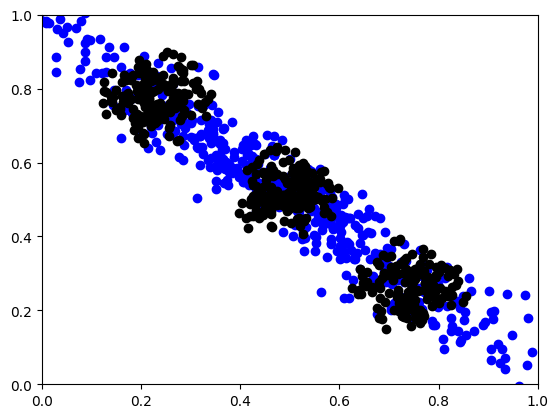

In [269]:
D2 = distr.Distribution("assets/test_distributions/diag.png")

result = param.fit_gaussian(D2)
param.plot_param_model(result, D2)

In [242]:
from itertools import product

np.random.seed(1)

D1  = distr.Distribution("assets/test_distributions/dist_one_side.png")

integral = D1.dist.sum() / (D1.width * D1.height)
norm_dist = np.divide(D1.dist, integral)

## pick some x-values and compute true log PDF
x_data = np.stack(list(product(np.arange(0, 1, 0.01), np.arange(0, 1, 0.01))))
# y_data = np.log(1e-6 + np.stack([D1.dist[int(point[1] * D1.height)][int(point[0] * D1.width)] for point in x_data]))
y_data = np.stack([norm_dist[int(point[1] * D1.height)][int(point[0] * D1.width)] for point in x_data])

# y_data = np.divide(y_data, np.sum(y_data))

def mul_gaussian(params):
    means = params[0: 2]
    cov_mat = stats.Covariance.from_cholesky([[params[2], 0], [params[3], params[4]]])

    estimated_y = stats.multivariate_normal.pdf(x_data, mean = means, cov = cov_mat, allow_singular=True)

    mse = abs(estimated_y - y_data).mean()

    return mse

# In Order: mean_x, mean_y, cholesky parameters a, b, c
initParams = [0.5, 0.5, 0.1, 0, 0.1]


results = minimize(mul_gaussian, initParams, method='Nelder-Mead')
print(results.x)

[0.2025944  0.5320231  0.07257336 0.0023057  0.11059006]


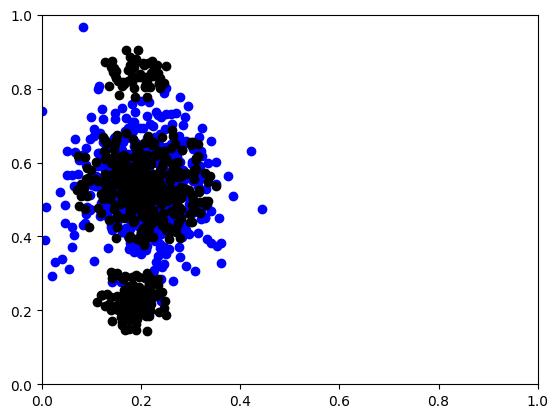

In [ ]:
mx, my, a, b, c = results.x
# a, b, c = 0.1, 0.1, 0.1

# mean = [0.5, 0.5]
mean = [mx, my]
cov = stats.Covariance.from_cholesky([[a, 0], [b, c]])

samples = stats.multivariate_normal(mean = mean, cov=cov).rvs(size = 500)
plot_points(samples, D1, True)

In [ ]:
# reconstruced_dist = np.zeros_like(D.dist)
reconstruced_dist = np.zeros([500, 500])

def eval_mul_gaus(params, point):
    mx, my, a, b, c = params
    mean = [mx, my]
    cov = stats.Covariance.from_cholesky([[a, 0], [b, c]])

    return stats.multivariate_normal(mean = mean, cov=cov).pdf(point)

shape = reconstruced_dist.shape
for y, row in enumerate(reconstruced_dist):
    for x in range(len(row)):
        x_loc = x / shape[0]
        y_loc = y / shape[1]
        reconstruced_dist[y][x] = eval_mul_gaus(results.x, [x_loc, y_loc])


In [254]:
rec_norm = np.multiply(reconstruced_dist, 255 / reconstruced_dist.max()).astype(np.uint8)
print(rec_norm.max())

255


In [255]:
sq_dist = 0

rec = rec_norm.astype(np.float32)
dist = D.dist.astype(np.float32)

for y, row in enumerate(reconstruced_dist):
    for x in range(len(row)):
        sq_dist += abs(rec[y][x] - dist[y][x])

print(sq_dist / (500* 500))

# for manual widening of distribution with a and c + 0.05 I got a average abs pixel dist of 13.382184

46.38363


In [256]:
cv2.imshow("reconstructed", rec_norm)
cv2.imshow("actual distribution", D1.dist)
    
cv2.waitKey()
cv2.destroyAllWindows()

# Mixture Model Implementation

# Can I do it in Torch ?

### Idea of process

##### Training

- Have a nn.module that computes the distribution
- Sample from currently modelled distribution (batched)
- Calculate (mean) loss to true distribution (Cross Entropy ?, KlD ?)
- backprop

In [3]:
import distribution as distr
import torch
from torch import nn
import tqdm

from normflows.distributions import ImagePrior

In [4]:
from GMM import GMM

In [21]:
num_gaussians = 4

init_means = torch.tensor([[0.5, 0.5], [-0.5, 0.5], [0.5, -0.5], [-0.5, -0.5]])
init_cholesky = torch.tensor([-2, 0.0, -2] * num_gaussians).reshape(num_gaussians, 3)

target = GMM(num_gaussians = num_gaussians, init_means=init_means, init_cholesky=init_cholesky)


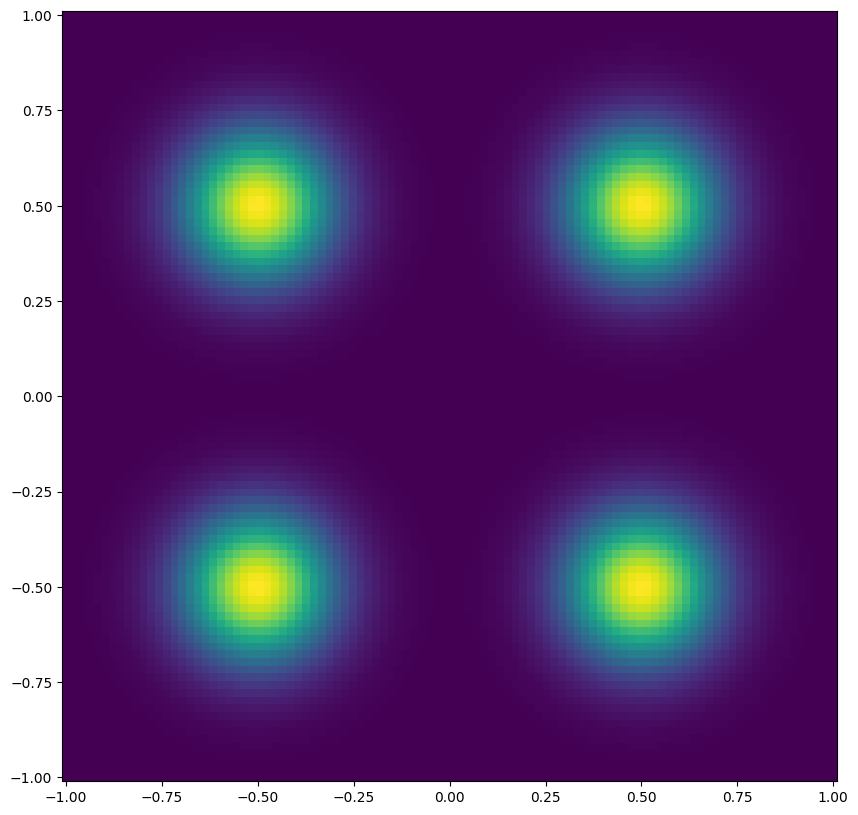

In [22]:
grid_size = 100

xs = torch.linspace(-1.0, 1.0, grid_size)
ys = torch.linspace(-1.0, 1.0, grid_size)
xx, yy = torch.meshgrid(xs, ys)
zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)

probs = target.prob(zz).view(*xx.shape)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.pcolormesh(xx, yy, probs.cpu().detach())

plt.show()

100%|██████████| 1000/1000 [00:03<00:00, 307.95it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4316.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


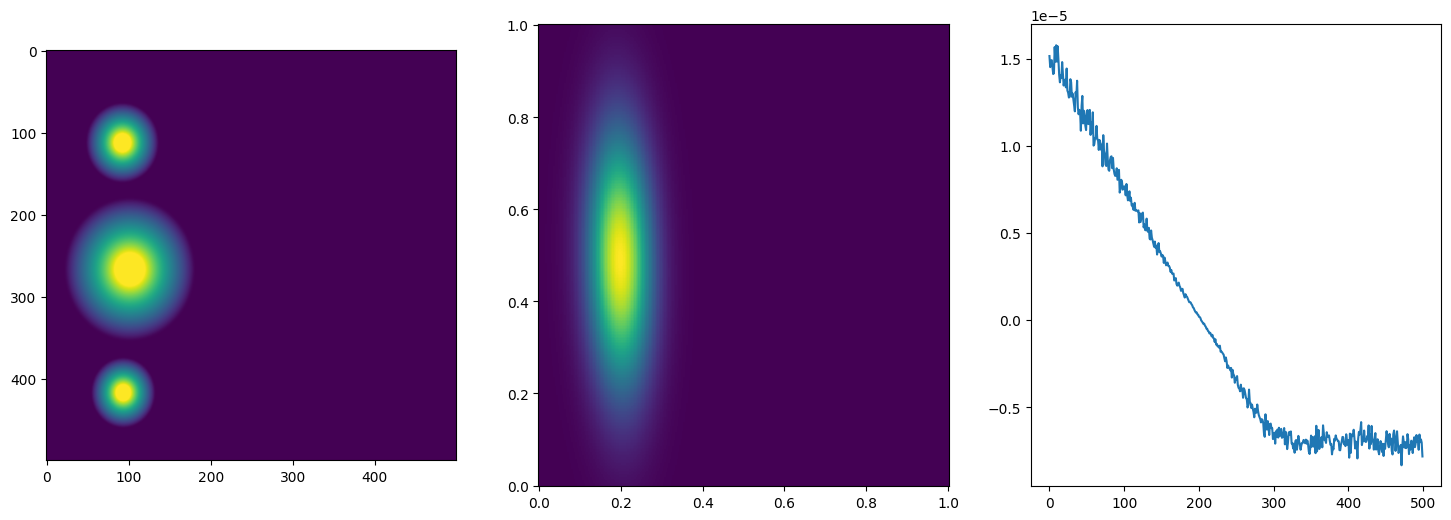

last loss: -7.822205589036457e-06
means: Parameter containing:
tensor([[0.2097, 0.4744],
        [0.1981, 0.4901],
        [0.2084, 0.4751]], device='cuda:0', requires_grad=True)
cov chol factors: Parameter containing:
tensor([[-1.5150, -0.0127, -1.3154],
        [-2.9304, -0.0119, -1.6606],
        [-1.3192, -0.0183, -1.1820]], device='cuda:0', requires_grad=True)
weights: tensor([ 0.0966, 20.4437,  0.0739], device='cuda:0', grad_fn=<ExpBackward0>)


In [6]:
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

# img = plt.imread('assets/test_distributions/Checkerboard.png') # Specify the path to your image here
img = plt.imread('assets/test_distributions/dist_one_side.png')[:, :, 0] # Specify the path to your image here
target = ImagePrior(img, x_range=[0, 1], y_range=[0, 1]).to(device)

mixture = GMM(3).to(device)

num_samples = 2 ** 12
max_iter = 1000
keep_regu = max_iter / 2

def train(target: ImagePrior, model: GMM):
    losses = []

    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-4)
    for it in tqdm.tqdm(range(max_iter)):
        optimizer.zero_grad()

        x = torch.rand((num_samples, 2), device=device)

        log_prob_p = target.log_prob(x)
        log_prob_q = model.log_prob(x)

        prob_p = torch.exp(log_prob_p)
        prob_q = torch.exp(log_prob_q)

        KLD_loss = -torch.mean(prob_p * log_prob_q)
        # rKLD_loss = torch.mean(prob_q * (log_prob_q - log_prob_p))

        loss = KLD_loss
        # loss = rKLD_loss
        
        if it == keep_regu:
            optimizer = torch.optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-4)

        if it < keep_regu:
            L2_weights = torch.nn.functional.softmax(model.weight_logits, dim = 0).square().sum()
            # L2_weights = model.weight_logits.exp().square().sum()
            loss += L2_weights
        else:
            losses.append(loss.mean().item())
        # loss = KLD_loss

        
        loss.backward()

        if it < keep_regu:
            pass
            model.weight_logits.grad.zero_()
            model.cholesky_params.grad.zero_()

        optimizer.step()

    return losses

losses = train(target, mixture)


grid_size = 300

xs = torch.linspace(0, 1, grid_size)
ys = torch.linspace(0, 1, grid_size)
xx, yy = torch.meshgrid(xs, ys)
zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2).to(device=device)

log_probs = mixture.prob(zz).view(*xx.shape)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
ax1.imshow(img)
ax2.pcolormesh(xx, yy, log_probs.cpu().detach().numpy())
ax3.plot(losses)
plt.show()

if not len(losses) == 0: print(f"last loss: {losses[-1]}")
print(f"means: {mixture.means}")
print(f"cov chol factors: {mixture.cholesky_params}")
print(f"weights: {torch.exp(mixture.weight_logits)}")

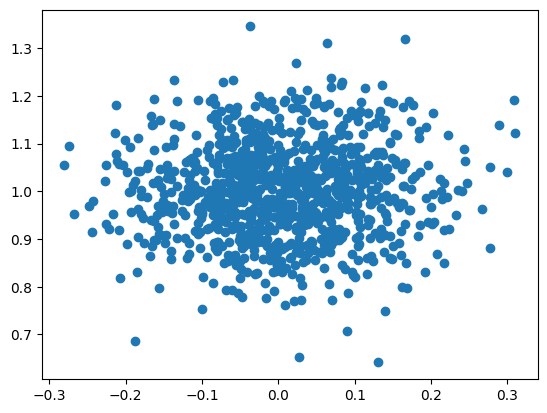

In [ ]:
test_mean = torch.tensor([0.0, 1.0])
test_cov = [0.1, 0.0, 0.1]
test_scale_tril = torch.tensor([[test_cov[0], 0], [test_cov[1], test_cov[2]]])

G = torch.distributions.MultivariateNormal(loc = test_mean, scale_tril=test_scale_tril)

samples = G.rsample([1000])

plt.figure()
plt.scatter(x = samples[: ,0], y = samples[: ,1])
plt.show()

In [72]:
D = 2
K = 2

tril_indices = torch.tril_indices(D, D, 0)
cholesky_params = nn.Parameter(
    torch.randn(K, len(tril_indices[0]))
)

print(tril_indices)
print(cholesky_params)

tensor([[0, 1, 1],
        [0, 0, 1]])
Parameter containing:
tensor([[-0.0767, -0.5382, -0.1893],
        [ 0.4910,  0.7127, -1.1272]], requires_grad=True)
